In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# Run this in a Colab cell
!pip install torch-scatter torch-sparse torch-geometric -f https://data.pyg.org/whl/torch-2.0.0+cu118.html


Looking in links: https://data.pyg.org/whl/torch-2.0.0+cu118.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 67.5 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 94.8 MB/s eta 0:00:00:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.5 MB/s eta 0:00:00a 0:00:01


In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
import matplotlib.pyplot as plt
from tqdm import tqdm

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Image Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 2. Custom Dataset
class MushroomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        for idx, label in enumerate(self.classes):
            for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
                self.images.append(img_path)
                self.labels.append(idx)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# 3. Train/Validation Split
indices = list(range(len(dataset)))
train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# 4. ConvNeXt Feature Extractor
class ConvNeXtFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(model.features.children()))

    def forward(self, x):
        return self.backbone(x)  # (B, C, H, W)

convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# 5. Convert CNN feature map to graph
def image_to_graph(features, label):
    B, C, H, W = features.shape
    graphs = []

    for b in range(B):
        feature_map = features[b]  # (C, H, W)
        x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

        # Grid edges
        edges = []
        for i in range(H):
            for j in range(W):
                idx = i * W + j
                if i + 1 < H:
                    edges.append((idx, idx + W))
                    edges.append((idx + W, idx))
                if j + 1 < W:
                    edges.append((idx, idx + 1))
                    edges.append((idx + 1, idx))

        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        y = torch.tensor([label[b]], dtype=torch.long)

        graphs.append(Data(x=x, edge_index=edge_index, y=y))

    return graphs

# 6. GCN Classifier
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = torch.mean(x, dim=0)  # Global mean pooling
        return self.fc(x)

gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# 7. Metrics Storage
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# 8. Training Loop
for epoch in range(10):
    gcn_model.train()
    total_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)

        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            optimizer.zero_grad()
            out = gcn_model(graph)
            loss = criterion(out.unsqueeze(0), graph.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pred = out.argmax().item()
            correct += int(pred == graph.y.item())
            total += 1

    train_acc = correct / total
    train_losses.append(total_loss)
    train_accuracies.append(train_acc)

    # Validation
    gcn_model.eval()
    val_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)
            graphs = image_to_graph(features.cpu(), label_batch.cpu())

            for graph in graphs:
                graph = graph.to(device)
                out = gcn_model(graph)
                loss = criterion(out.unsqueeze(0), graph.y)
                val_loss += loss.item()
                pred = out.argmax().item()
                correct += int(pred == graph.y.item())
                total += 1

    val_acc = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# 9. Plotting Loss & Accuracy
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Over Epochs")
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Over Epochs")
plt.legend()

plt.tight_layout()
plt.show()


/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:86: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-scatter'. "
/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:124: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-sparse'. "
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:01<00:00, 85.3MB/s] 
Epoch 1 - Train:   0%|          | 1/368 [00:04<30:31,  4.99s/it]/usr/local/lib/python3.11

Epoch 1 | Train Loss: 12646.6347 | Train Acc: 0.9139 | Val Loss: 1197.4531 | Val Acc: 0.9683


Epoch 2 - Val: 100%|██████████| 92/92 [05:30<00:00,  3.59s/it]


Epoch 2 | Train Loss: 3718.9332 | Train Acc: 0.9747 | Val Loss: 1213.9163 | Val Acc: 0.9707


Epoch 3 - Val: 100%|██████████| 92/92 [05:28<00:00,  3.57s/it]


...

Epoch 5 - Val: 100%|██████████| 92/92 [05:41<00:00,  3.71s/it]


Epoch 5 | Train Loss: 1694.4087 | Train Acc: 0.9892 | Val Loss: 918.5204 | Val Acc: 0.9832


Epoch 6 - Val: 100%|██████████| 92/92 [05:49<00:00,  3.79s/it]


Epoch 6 | Train Loss: 1681.9238 | Train Acc: 0.9902 | Val Loss: 561.2143 | Val Acc: 0.9892


Epoch 7 - Train:  21%|██        | 77/368 [05:18<22:27,  4.63s/it]

/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:86: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-scatter'. "
/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:124: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-sparse'. "
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:00<00:00, 193MB/s] 
Epoch 1 - Train:   2%|▏         | 6/368 [00:23<21:53,  3.63s/it]/usr/local/lib/python3.11/

Epoch 1 | Train Loss: 12731.8216 | Train Acc: 0.9122 | Val Loss: 1339.4648 | Val Acc: 0.9639


Epoch 2 - Val: 100%|██████████| 92/92 [05:47<00:00,  3.78s/it]


Epoch 2 | Train Loss: 3749.6938 | Train Acc: 0.9746 | Val Loss: 793.7901 | Val Acc: 0.9799


Epoch 3 - Val: 100%|██████████| 92/92 [05:34<00:00,  3.63s/it]


...

Epoch 9 - Val: 100%|██████████| 92/92 [05:34<00:00,  3.63s/it]


Epoch 9 | Train Loss: 1443.2806 | Train Acc: 0.9925 | Val Loss: 1569.5402 | Val Acc: 0.9803


Epoch 10 - Val: 100%|██████████| 92/92 [05:25<00:00,  3.53s/it]


Epoch 10 | Train Loss: 1301.6370 | Train Acc: 0.9936 | Val Loss: 778.7625 | Val Acc: 0.9895


Final Metrics: 100%|██████████| 92/92 [05:08<00:00,  3.35s/it]


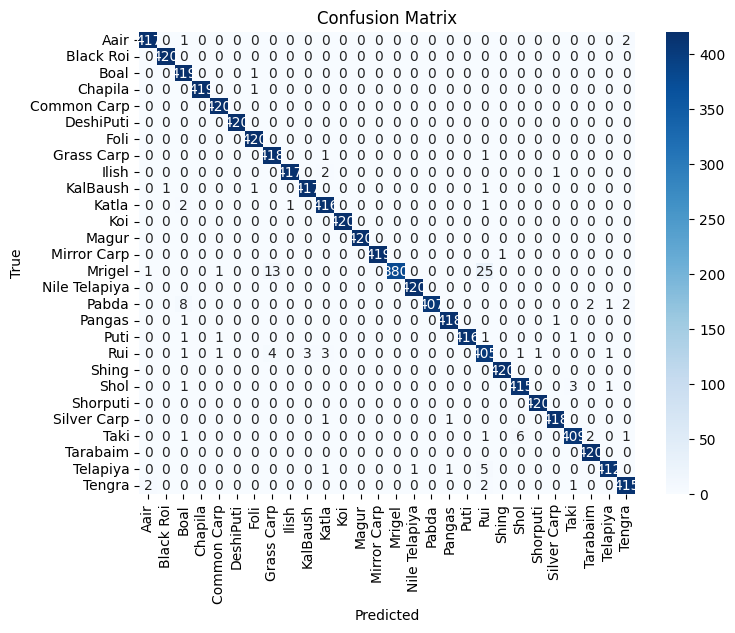

Classification Report:
               precision    recall  f1-score   support

         Aair       0.99      0.99      0.99       420
    Black Roi       1.00      1.00      1.00       420
         Boal       0.96      1.00      0.98       420
      Chapila       1.00      1.00      1.00       420
  Common Carp       0.99      1.00      1.00       420
    DeshiPuti       1.00      1.00      1.00       420
         Foli       0.99      1.00      1.00       420
   Grass Carp       0.96      1.00      0.98       420
        Ilish       1.00      0.99      1.00       420
     KalBaush       0.99      0.99      0.99       420
        Katla       0.98      0.99      0.99       420
          Koi       1.00      1.00      1.00       420
        Magur       1.00      1.00      1.00       420
  Mirror Carp       1.00      1.00      1.00       420
       Mrigel       1.00      0.90      0.95       420
Nile Telapiya       1.00      1.00      1.00       420
        Pabda       1.00      0.97      0

ROC Probabilities:   2%|▏         | 2/92 [00:06<04:58,  3.31s/it]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
ROC Probabilities:  38%|███▊      | 35/92 [02:02<03:07,  3.28s/it]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
ROC Probabilities: 100%|██████████| 92/92 [05:18<00:00,  3.46s/it]


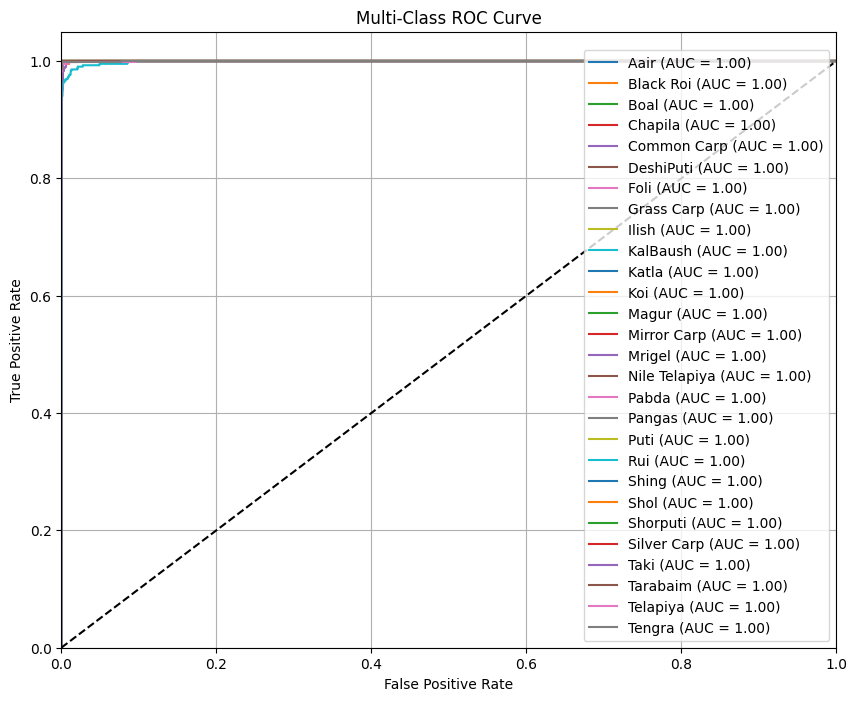

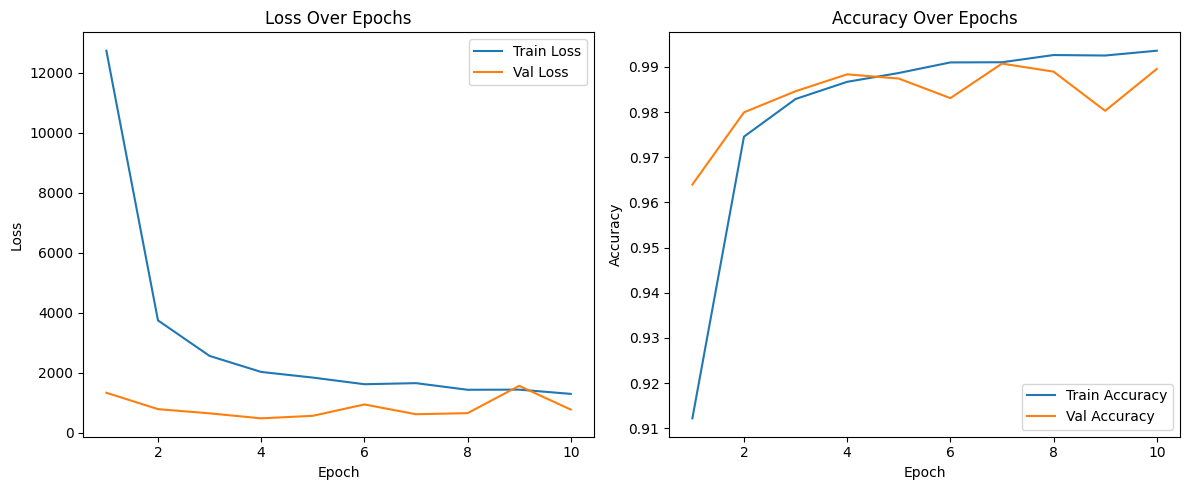

In [3]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Image Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 2. Custom Dataset
class MushroomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        for idx, label in enumerate(self.classes):
            for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
                self.images.append(img_path)
                self.labels.append(idx)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

dataset = MushroomDataset(root_dir="/kaggle/input/split-dataset-of-fish/split dataset of fish/train", transform=transform)

# 3. Train/Validation Split
indices = list(range(len(dataset)))
train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=dataset.labels, random_state=42)
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

# 4. ConvNeXt Feature Extractor
class ConvNeXtFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(model.features.children()))

    def forward(self, x):
        return self.backbone(x)  # (B, C, H, W)

convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# 5. Convert CNN feature map to graph
def image_to_graph(features, label):
    B, C, H, W = features.shape
    graphs = []

    for b in range(B):
        feature_map = features[b]  # (C, H, W)
        x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

        # Grid edges
        edges = []
        for i in range(H):
            for j in range(W):
                idx = i * W + j
                if i + 1 < H:
                    edges.append((idx, idx + W))
                    edges.append((idx + W, idx))
                if j + 1 < W:
                    edges.append((idx, idx + 1))
                    edges.append((idx + 1, idx))

        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        y = torch.tensor([label[b]], dtype=torch.long)

        graphs.append(Data(x=x, edge_index=edge_index, y=y))

    return graphs

# 6. GCN Classifier
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = torch.mean(x, dim=0)  # Global mean pooling
        return self.fc(x)

gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# 7. Metrics Storage
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# 8. Training Loop
for epoch in range(10):
    gcn_model.train()
    total_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)

        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            optimizer.zero_grad()
            out = gcn_model(graph)
            loss = criterion(out.unsqueeze(0), graph.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pred = out.argmax().item()
            correct += int(pred == graph.y.item())
            total += 1

    train_acc = correct / total
    train_losses.append(total_loss)
    train_accuracies.append(train_acc)

    # Validation
    gcn_model.eval()
    val_loss = 0
    correct = 0
    total = 0

    for img_batch, label_batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Val"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)
            graphs = image_to_graph(features.cpu(), label_batch.cpu())

            for graph in graphs:
                graph = graph.to(device)
                out = gcn_model(graph)
                loss = criterion(out.unsqueeze(0), graph.y)
                val_loss += loss.item()
                pred = out.argmax().item()
                correct += int(pred == graph.y.item())
                total += 1

    val_acc = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {total_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# 9. Final Evaluation with Metrics
all_preds = []
all_labels = []

for img_batch, label_batch in tqdm(val_loader, desc="Final Metrics"):
    img_batch = img_batch.to(device)
    label_batch = label_batch.to(device)

    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for i, graph in enumerate(graphs):
            graph = graph.to(device)
            out = gcn_model(graph)
            pred = out.argmax().item()
            true = graph.y.item()
            all_preds.append(pred)
            all_labels.append(true)

# Confusion Matrix
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=dataset.classes))

# ROC Curve
n_classes = len(dataset.classes)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
y_pred_prob = np.zeros((len(y_pred), n_classes))

counter = 0
for img_batch, label_batch in tqdm(val_loader, desc="ROC Probabilities"):
    img_batch = img_batch.to(device)
    label_batch = label_batch.to(device)

    with torch.no_grad():
        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            out = gcn_model(graph)
            probs = F.softmax(out, dim=0).cpu().numpy()
            y_pred_prob[counter] = probs
            counter += 1

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{dataset.classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# 10. Plotting Loss & Accuracy
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Over Epochs")
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Over Epochs")
plt.legend()

plt.tight_layout()
plt.show()


In [6]:
# Final Train and Validation Accuracy
final_train_acc = train_accuracies[-1]
final_val_acc = val_accuracies[-1]

print(f"\n✅ Final Train Accuracy: {final_train_acc * 100:.2f}%")
print(f"✅ Final Validation Accuracy: {final_val_acc * 100:.2f}%")



✅ Final Train Accuracy: 99.36%
✅ Final Validation Accuracy: 98.95%
